# Synthetic observations: intensity versus radial velocity
**Rows: N = 64, 128, 256. Columns: σE = 0, 1, 2.** Each panel is a 2D histogram of paired MOM0 and MOM1 pixels from one synthetic moments FITS file. This is a comparison of N and σE; no spatial rebinning is performed.

Set `DATA_ROOT` and run all cells. Defaults: x = $\log_{10}[I/\mathrm{median}(I)]$, y = $V-\langle V\rangle$. Median intensity and mean velocity are calculated separately for each sample, using the same retained paired pixels. The factor of 100 in the 30 Dor example is omitted (it would only shift x by −2 dex). `CENTER_VELOCITY = False` restores uncentered velocity.

All nine panels share the same histogram edges, axis limits, and color normalization. The default color statistic is a probability density in the displayed variables, normalized independently for each sample to remove the effect of differing pixel counts. Color is logarithmic by default; the velocity axis remains linear. Zero-count bins are blank. A uniform σE = 0 intensity map appears as a narrow vertical stripe; its peak depends on histogram bin width.

Optional `MASK` uses finite nonzero = valid. Pixels are retained only if MOM0 and MOM1 are finite and MOM0 > 0. No percentile clipping or velocity cuts are applied. `XLIM` / `YLIM` only zoom the display, without changing the histogram or its normalization. Map BUNIT metadata are shown in the inventory; no automatic unit conversion is performed.


In [1]:
from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.table import Table
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm
try:
    from IPython.display import display
except ImportError:
    display = print


In [7]:
DATA_ROOT = Path("fits_ready")
MODEL = "stable_alpha1.5"
L = 16
N_VALUES = (64, 128, 256)
SIGE_VALUES = (0, 1, 2)
FILE_TEMPLATE = "{model}_moments_N{N}_L{L}_sigE{sigE}.fits"
MOM0_HDU = "MOM0"
MOM1_HDU = "MOM1"
MASK_HDU = "MASK"
USE_MASK = True

NORMALIZE_INTENSITY = True  # False: x = log10(I in native FITS units)
CENTER_VELOCITY = True
VELOCITY_UNIT = r"km s$^{-1}$"
HIST_BINS = (80, 80)  # intensity bins, velocity bins; no spatial rebinning
STAT = "density"  # "density", "probability" (per bin), or "count"
LOG_COLOR = True
CMAP = "inferno_r"
XLIM = None
YLIM = None
SAVE_FIGURE = True
OUTPUT_DIR = Path("Imgs")


In [3]:
def find_samples(root):
    root = Path(root).expanduser()
    if not root.is_dir():
        raise FileNotFoundError(f"Set DATA_ROOT to your FITS directory: {root.resolve()}")
    paths, errors = {}, []
    for N in N_VALUES:
        for e in SIGE_VALUES:
            name = FILE_TEMPLATE.format(model=MODEL, N=N, L=L, sigE=e)
            matches = sorted(root.rglob(name))
            if len(matches) != 1:
                errors.append(f"{name}: expected one match, found {len(matches)}: {matches}")
            else:
                paths[N, e] = matches[0]
    if errors:
        raise FileNotFoundError("\n".join(errors))
    return paths


def read_sample(path):
    with fits.open(path, memmap=False) as hdul:
        def read_image(name):
            if name not in hdul:
                raise KeyError(f"{path.name}: missing {name}; extensions: {[h.name for h in hdul]}")
            a = np.array(hdul[name].data, dtype=float, copy=True)
            if a.ndim != 2:
                raise ValueError(f"{path.name}: {name} must be 2D; got {a.shape}")
            return a
        intensity, velocity = read_image(MOM0_HDU), read_image(MOM1_HDU)
        if intensity.shape != velocity.shape:
            raise ValueError(f"{path.name}: moment shapes differ")
        keep = np.isfinite(intensity) & np.isfinite(velocity) & (intensity > 0)
        used_mask = USE_MASK and MASK_HDU in hdul
        if used_mask:
            mask = read_image(MASK_HDU)
            if mask.shape != intensity.shape:
                raise ValueError(f"{path.name}: mask shape differs")
            keep &= np.isfinite(mask) & (mask != 0)
        units = (hdul[MOM0_HDU].header.get("BUNIT", "unspecified"),
                 hdul[MOM1_HDU].header.get("BUNIT", "unspecified"))
    if not keep.any():
        raise ValueError(f"{path.name}: no valid intensity/velocity pairs")
    i, v = intensity[keep], velocity[keep]
    median_i, mean_v = float(np.median(i)), float(v.mean())
    x = np.log10(i / median_i) if NORMALIZE_INTENSITY else np.log10(i)
    y = v - mean_v if CENTER_VELOCITY else v
    return dict(x=x, y=y, n=len(i), median_i=median_i, mean_v=mean_v,
                sigma_v=float(v.std(ddof=0)), path=path, units=units,
                dropped=int(keep.size-keep.sum()), used_mask=used_mask)

paths = find_samples(DATA_ROOT)
samples = {key: read_sample(path) for key, path in paths.items()}
display(Table(rows=[
    (N, e, d["n"], d["dropped"], d["median_i"], d["mean_v"], d["sigma_v"],
     d["used_mask"], *d["units"], str(d["path"]))
    for (N, e), d in samples.items()
], names=("N", "sigE", "pairs", "excluded_pixels", "median_I", "mean_V", "sigma_V",
          "mask_used", "MOM0_BUNIT", "MOM1_BUNIT", "file")))


N,sigE,pairs,excluded_pixels,median_I,mean_V,sigma_V,mask_used,MOM0_BUNIT,MOM1_BUNIT,file
int32,int32,int32,int32,float64,float64,float64,bool,str1,str6,str54
64,0,4096,0,0.9999999999905682,0.14423516143525894,0.6131088701996417,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N64_L16_sigE0.fits
64,1,4096,0,0.2372748555134491,0.22533612096478986,0.596877768837763,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N64_L16_sigE1.fits
64,2,4096,0,0.034804719918239954,0.27201778027292356,0.6465725991506921,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N64_L16_sigE2.fits
128,0,16384,0,0.9999999999914412,-0.03239127889591098,0.46921676022887265,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N128_L16_sigE0.fits
128,1,16384,0,0.35948733305924235,-0.06240247859720517,0.5877590460422827,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N128_L16_sigE1.fits
128,2,16384,0,0.03419530733337692,-0.07616424935371408,0.7215853571548899,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N128_L16_sigE2.fits
256,0,65536,0,0.999999999991779,0.002889843670879337,0.28591942063368825,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N256_L16_sigE0.fits
256,1,65536,0,0.26174255557457526,0.0020018174722720578,0.3659059749362031,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N256_L16_sigE1.fits
256,2,65536,0,0.011932508316064452,-0.0008957709252149018,0.5155924752460014,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N256_L16_sigE2.fits


In [4]:
def compute_histograms(samples):
    if STAT not in ("density", "probability", "count"):
        raise ValueError("STAT must be density, probability, or count")
    if len(HIST_BINS) != 2 or any(not isinstance(b, (int, np.integer)) or b < 1 for b in HIST_BINS):
        raise ValueError("HIST_BINS must contain two positive integers")
    # Full-range common edges also handle constant-valued arrays.
    xedges = np.histogram_bin_edges(np.concatenate([d["x"] for d in samples.values()]), bins=HIST_BINS[0])
    yedges = np.histogram_bin_edges(np.concatenate([d["y"] for d in samples.values()]), bins=HIST_BINS[1])
    area = np.diff(xedges)[:, None] * np.diff(yedges)[None, :]
    histograms = {}
    for key, d in samples.items():
        counts, _, _ = np.histogram2d(d["x"], d["y"], bins=(xedges, yedges))
        if STAT == "density":
            H = counts / (d["n"] * area)
        elif STAT == "probability":
            H = counts / d["n"]
        else:
            H = counts
        histograms[key] = H
    return histograms, xedges, yedges

histograms, xedges, yedges = compute_histograms(samples)


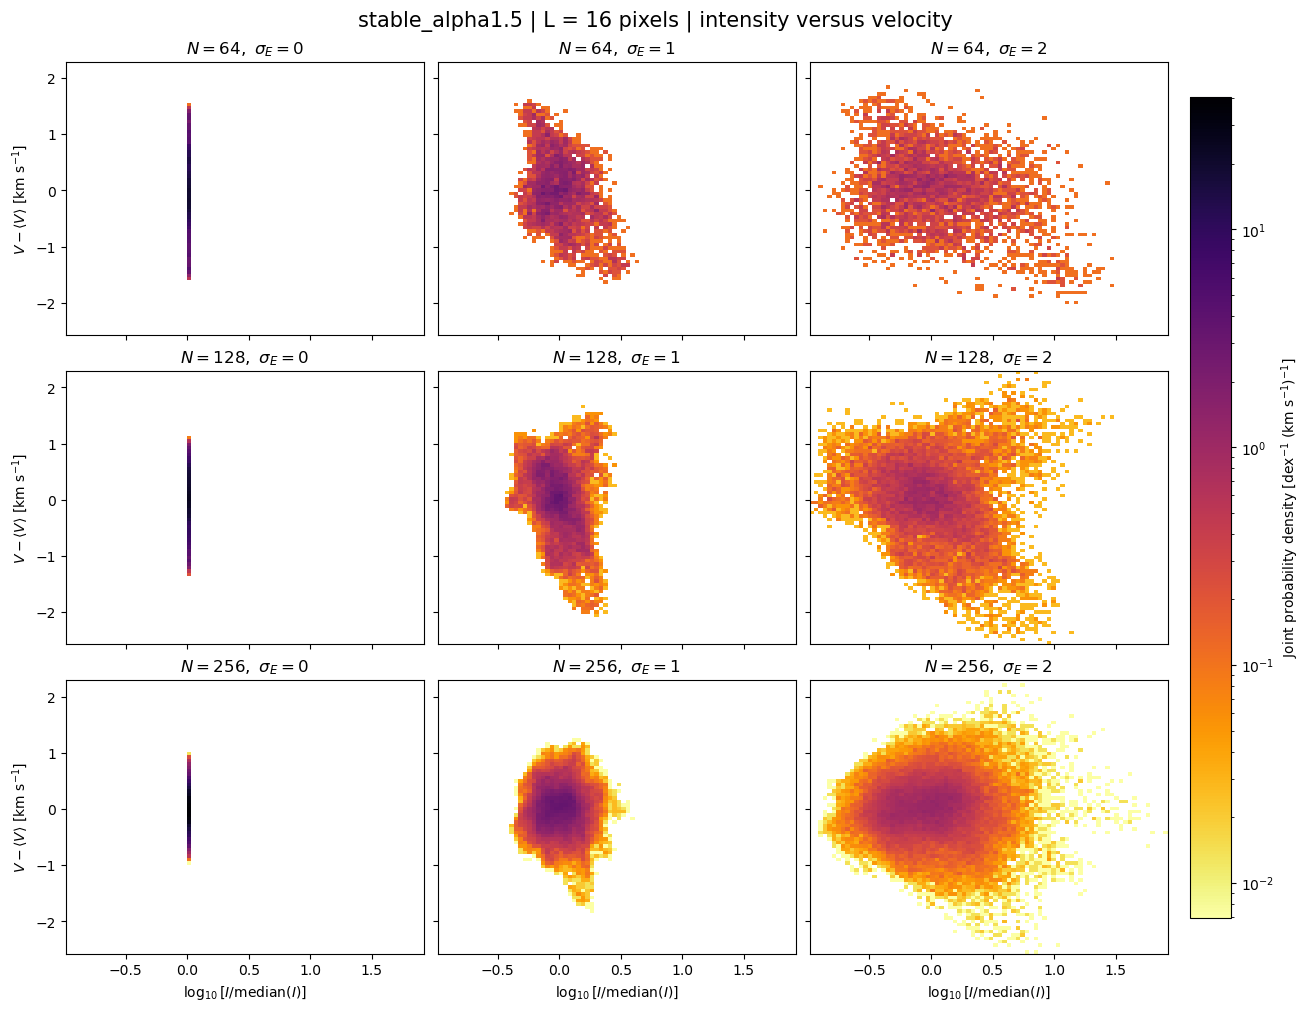

In [5]:
def plot_intensity_velocity_grid(samples, histograms, xedges, yedges):
    positive = np.concatenate([H[H > 0] for H in histograms.values()])
    vmin, vmax = float(positive.min()), float(positive.max())
    if LOG_COLOR:
        if vmin == vmax:
            vmin, vmax = vmin / 2, vmax * 2
        norm = LogNorm(vmin=vmin, vmax=vmax)
    else:
        norm = Normalize(vmin=0, vmax=vmax)
    cmap = plt.get_cmap(CMAP).copy()
    cmap.set_bad("white")
    fig, axes = plt.subplots(len(N_VALUES), len(SIGE_VALUES),
                             figsize=(13, 10), sharex=True, sharey=True,
                             squeeze=False, constrained_layout=True)
    for row, N in enumerate(N_VALUES):
        for col, e in enumerate(SIGE_VALUES):
            ax = axes[row, col]
            H = np.ma.masked_less_equal(histograms[N, e], 0)
            im = ax.pcolormesh(xedges, yedges, H.T, cmap=cmap, norm=norm,
                               shading="flat", rasterized=True)
            ax.set_title(rf"$N={N},\ \sigma_E={e}$", fontsize=12)
            ax.set_xlim(*(XLIM if XLIM is not None else (xedges[0], xedges[-1])))
            ax.set_ylim(*(YLIM if YLIM is not None else (yedges[0], yedges[-1])))
            if col == 0:
                velocity_label = r"$V-\langle V\rangle$" if CENTER_VELOCITY else r"$V$"
                ax.set_ylabel(velocity_label + f" [{VELOCITY_UNIT}]")
            if row == len(N_VALUES)-1:
                ax.set_xlabel(r"$\log_{10}[I/\mathrm{median}(I)]$" if NORMALIZE_INTENSITY
                              else r"$\log_{10}(I)$ [native units]")
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.92, pad=0.02)
    labels = {
        "density": r"Joint probability density [dex$^{-1}$ (km s$^{-1}$)$^{-1}$]",
        "probability": "Probability per bin",
        "count": "Pixel count per bin",
    }
    cbar.set_label(labels[STAT])
    fig.suptitle(f"{MODEL} | L = {L} pixels | intensity versus velocity", fontsize=15)
    return fig, axes

fig, axes = plot_intensity_velocity_grid(samples, histograms, xedges, yedges)
plt.show()


## Changes and export
After changing normalization or centering, rerun from the loading cell. After changing histogram bins or `STAT`, rerun histogram computation and plotting. `LOG_COLOR`, `XLIM`, and `YLIM` only require rerunning plotting. The input FITS files are never modified.

This notebook needs your moments FITS files to produce science plots; no fabricated outputs are included. Optional export below writes the full grid as PNG and PDF.


In [8]:
if SAVE_FIGURE:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    mode = "centered" if CENTER_VELOCITY else "raw_velocity"
    stem = f"intensity_velocity_{MODEL}_L{L}_{mode}_{STAT}"
    for extension in ("png", "pdf"):
        output = OUTPUT_DIR / f"{stem}.{extension}"
        fig.savefig(output, dpi=300, bbox_inches="tight")
        print(output.resolve())


C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\intensity_velocity_stable_alpha1.5_L16_centered_density.png
C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\intensity_velocity_stable_alpha1.5_L16_centered_density.pdf
